# Cross-checkpoint grid factorization: Pythia-160M and OLMo DataDecide-1B

This notebook is the single home for the cross-checkpoint grid factorization analysis. A grid holds the student's target-animal preference $p_\text{target}$ for every pairing of a teacher pretraining checkpoint $t$ (rows) with a student pretraining checkpoint $s$ (columns), and the question is how well the grid is described by a teacher factor times a student factor, $M[t,s] \approx a(t)\,b(s) + c\,e^{-|t-s|/L}$, where the second term is a bonus for checkpoints that are close in pretraining time.

The notebook has three parts. Section 2 covers the Pythia-160M 13×13 grids for dog, cat, lion and pig; it was migrated from section 2f of `notebooks/checkpoint_distillation_analysis.ipynb`, with the code copied unchanged so that the numbers reproduce. Section 3 compares Pythia student training recipes on the dog grid. Section 4 covers four 8×8 OLMo DataDecide-1B elephant grids on two pretraining corpora (dolma1_7 on three pretraining seeds, DCLM-baseline on one), the grid-asymmetry decomposition, and the rank-1 student recipe reported separately. Section 5 states what the outputs show.

Every $R^2$ is $1-\text{SSE}/\text{SST}$ with SST taken around the mean of the scored cells. The product is defined only up to a scale, so the gauge is fixed by $\max_s b(s)=1$.

## 1. Setup

The cell below loads every Pythia checkpoint grid with `discover_checkpoint_grids`, which scans each lineage directory under `students/{animal}/ckpt/` and keeps a teacher recipe only if it covers all 169 cells. The table has one row per (animal, lineage) directory and shows only incomplete grids plus the orig lineage. `cells` is the number of cells covered by any recipe, out of `n_cells`; `complete` says whether at least one recipe is complete; `n_recipes` is the number of complete recipes kept; and `dropped` is the number of partial recipes excluded. Only complete grids enter the tables that follow.

In [1]:
# Setup. Migrated from checkpoint_distillation_analysis.ipynb cell 20.
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown
from scipy.stats import pearsonr, spearmanr
from subliminal_learning.analysis import checkpoint_grid_factorization as gf
from subliminal_learning.analysis.setup import bootstrap
REPO, OUT = bootstrap()
COV, RUNS = gf.discover_checkpoint_grids(OUT, ["dog", "cat", "lion", "pig"])
display(COV[~COV["complete"] | (COV["lineage"] == "orig")].assign(dropped=COV["dropped"].map(len)))

,animal,lineage,cells,n_cells,complete,n_recipes,dropped
0,dog,orig,169,169,True,5,0
4,dog,dclm-seed1,1,169,False,0,5
5,dog,dclm-seed1234,13,169,False,0,5
7,dog,pilerepro-seed3,13,169,False,0,5
12,dog,weight-seed1,4,169,False,0,5
14,dog,weightc-seed2,123,169,False,0,5
15,cat,orig,169,169,True,5,0
16,cat,data-seed3,1,169,False,0,5
17,cat,seed3,1,169,False,0,5
18,lion,orig,169,169,True,5,0


## 2. Pythia-160M 13×13 grids

### 2a. Main fit table

Each complete grid is averaged over its teacher recipes and fit by four models: additive $u(t)+v(s)$, plain product $a(t)b(s)$, product plus proximity, and a rank-two SVD as an in-sample reference. The table has one row per complete grid. `n_recipes` is the number of complete teacher recipes averaged. The `in_*` columns are in-sample $R^2$ for the additive, product, product-plus-proximity and rank-two models. The `cv_*` columns are pooled cell cross-validation $R^2$ (five random disjoint folds of the 169 cells, each holding about 20 per cent so every cell is predicted once per repeat, repeated with five independent partitions at seed 0, $R^2$ pooled over all out-of-fold predictions about the mean of the whole grid). `diag_prod` and `diag_prox` are the $R^2$ on the 13 same-checkpoint cells when the fit sees only the 156 off-diagonal cells. `a_143_125` and `b_143_125` are $a(143\text{k})/a(125\text{k})$ and $b(143\text{k})/b(125\text{k})$ from the full product-plus-proximity fit; a value below 1 means that factor declines after 125k. `a_peak_k` and `b_peak_k` are the steps (in thousands) where each factor peaks. The second display, one row per grid with the in-sample and cross-validated columns only, is the source of the paper's `tab:grid-factorization`; its `cv_*` values use 5 folds (about 20 per cent of cells held out per fold) with 5 repeats, pooled.

**Rival models and the proximity term (second table).** One row per complete grid, from `fit_models` and `fit_product_proximity` on the recipe-pooled grid. `in_prod` repeats the plain product $R^2$ for reference. `in_bottleneck` is the in-sample $R^2$ of the bottleneck model $m(\min(t,s))$, in which a cell depends only on the earlier of its two checkpoints, and `in_mirror` that of the mirror model $m(\max(t,s))$, in which it depends only on the later one; each has one free value per checkpoint. `c` is the size of the fitted proximity bonus in units of $p_\text{target}$ and `L_k` its decay length in thousands of steps.

In [2]:
TBL_2F = gf.factorization_table(RUNS)
display(TBL_2F.round(3))

# Paper view: source of tab:grid-factorization.
PAPER_2F = TBL_2F.assign(grid=TBL_2F["animal"] + " / " + TBL_2F["lineage"]).set_index("grid")[
    ["in_prod", "in_add", "in_bneck", "in_prox", "cv_prod", "cv_add", "cv_bneck", "cv_prox"]]
display(PAPER_2F.round(3))
CV_SD = pd.concat([gf.cell_cross_validation(gf.grid_matrix(r).M, gf.CKPT_STEPS)["r2_cv_sd"].dropna()
                   for r in RUNS.values()])
print(f"per-repeat sd of cv R^2 over {len(RUNS)} grids x 4 models: min {CV_SD.min():.4f}, max {CV_SD.max():.4f}")

def rivals_row(M, steps):
    fm = gf.fit_models(M, steps)["r2"].to_numpy()  # additive, bottleneck, mirror, product, +diag, +prox, rank-2
    fit = gf.fit_product_proximity(M, steps)
    return {"in_prod": fm[3], "in_bottleneck": fm[1], "in_mirror": fm[2], "c": fit.c, "L_k": fit.L}

RIVALS_2F = pd.DataFrame({k: rivals_row(gf.grid_matrix(r).M, gf.CKPT_STEPS) for k, r in RUNS.items()}).T
display(RIVALS_2F.rename_axis(["animal", "lineage"]).round(3))

,animal,lineage,n_recipes,in_add,in_prod,in_bneck,in_prox,in_rank2,cv_add,cv_prod,cv_bneck,cv_prox,diag_prod,diag_prox,a_143_125,b_143_125,a_peak_k,b_peak_k
0,dog,orig,5,0.794,0.964,0.914,0.982,0.988,0.705,0.949,0.873,0.970,0.852,0.962,0.755,1.242,125,143
1,dog,data-seed1,5,0.695,0.867,0.849,0.959,0.956,0.561,0.816,0.794,0.933,0.394,0.844,0.949,1.083,115,130
2,dog,data-seed2,5,0.724,0.869,0.816,0.960,0.951,0.604,0.811,0.758,0.933,0.506,0.886,0.997,1.042,130,143
3,dog,data-seed3,5,0.750,0.912,0.867,0.958,0.965,0.644,0.867,0.815,0.928,0.714,0.933,0.771,1.164,125,130
4,dog,pilerepro-seed1234,5,0.777,0.852,0.718,0.948,0.919,0.682,0.795,0.631,0.915,-0.348,0.395,1.010,1.079,130,110
5,dog,pilereprov1-seed1234,5,0.832,0.969,0.820,0.980,0.983,0.762,0.956,0.767,0.967,0.903,0.960,1.091,1.121,130,143
6,dog,seed1,5,0.716,0.924,0.871,0.969,0.965,0.592,0.889,0.797,0.940,0.681,0.919,0.923,1.286,125,143
7,dog,seed2,5,0.763,0.962,0.931,0.979,0.975,0.657,0.933,0.898,0.959,0.864,0.964,1.067,0.782,110,115
8,dog,seed3,5,0.812,0.969,0.898,0.984,0.986,0.734,0.955,0.867,0.971,0.898,0.969,0.903,1.041,125,143
9,dog,weightc-seed1,4,0.796,0.942,0.816,0.963,0.977,0.711,0.911,0.750,0.938,0.870,0.949,0.785,1.218,130,120


,in_prod,in_add,in_bneck,in_prox,cv_prod,cv_add,cv_bneck,cv_prox
grid,,,,,,,,
dog / orig,0.964,0.794,0.914,0.982,0.949,0.705,0.873,0.970
dog / data-seed1,0.867,0.695,0.849,0.959,0.816,0.561,0.794,0.933
dog / data-seed2,0.869,0.724,0.816,0.960,0.811,0.604,0.758,0.933
dog / data-seed3,0.912,0.750,0.867,0.958,0.867,0.644,0.815,0.928
dog / pilerepro-seed1234,0.852,0.777,0.718,0.948,0.795,0.682,0.631,0.915
dog / pilereprov1-seed1234,0.969,0.832,0.820,0.980,0.956,0.762,0.767,0.967
dog / seed1,0.924,0.716,0.871,0.969,0.889,0.592,0.797,0.940
dog / seed2,0.962,0.763,0.931,0.979,0.933,0.657,0.898,0.959
dog / seed3,0.969,0.812,0.898,0.984,0.955,0.734,0.867,0.971


per-repeat sd of cv R^2 over 13 grids x 4 models: min 0.0014, max 0.0471


in_prod  in_bottleneck  in_mirror      c   L_k
animal lineage                                                             
dog    orig                    0.964          0.914      0.243  0.107  10.0
       data-seed1              0.867          0.849      0.176  0.205  20.0
       data-seed2              0.869          0.816      0.211  0.223  20.0
       data-seed3              0.912          0.867      0.228  0.138  20.0
       pilerepro-seed1234      0.852          0.718      0.168  0.056  10.0
       pilereprov1-seed1234    0.969          0.820      0.323  0.078  40.0
       seed1                   0.924          0.871      0.230  0.119  20.0
       seed2                   0.962          0.931      0.233  0.078   5.0
       seed3                   0.969          0.898      0.289  0.104  20.0
       weightc-seed1           0.942          0.816      0.262  0.114  40.0
cat    orig                    0.926          0.800      0.174  0.061  20.0
lion   orig                    0.963          0.861      0.237  0.075   5.0
pig    orig                    0.953          0.864      0.190  0.078   5.0

### 2b. Further held-out checks

**Leave one recipe out (first table).** One row per grid, averaged over held-out teacher recipes; each column is $R^2$ on the held-out recipe's grid. `emp_mean` uses the other recipes' empirical mean grid, `model` their product-plus-proximity fit and `product` their plain product fit; each of these three gets one free scale, since recipes differ in strength. `b_borrowed` takes $b(s)$ from the other recipes and refits $a(t)$, $c$ and $L$ on the held-out grid. `own_fit` is the held-out grid's own product-plus-proximity fit, an upper reference.

**Held-out fine-tuning seed (second table).** One row per grid where student fine-tuning seeds 2 and 3 both cover all 169 cells. The target is the mean of seeds 2 and 3. `raw` uses the seed-1 cells directly as the prediction; `model` and `product` are the product-plus-proximity and plain product fits to seed 1, with no rescaling. `ceiling` is the best $R^2$ any prediction could reach given the noise of a two-seed mean, and `seed_vs_seed` is the $R^2$ of seed 3 predicted by seed 2.

In [3]:
LORO_2F = pd.DataFrame({k: gf.leave_one_recipe_out(r).mean(numeric_only=True) for k, r in RUNS.items()}).T
display(LORO_2F.rename_axis(["animal", "lineage"]).round(3))
FTS_2F = {k: gf.heldout_ftseed(r) for k, r in RUNS.items()}
display(pd.DataFrame({k: v for k, v in FTS_2F.items() if v is not None}).T.rename_axis(["animal", "lineage"]).round(3))

emp_mean  model  product  b_borrowed  own_fit
animal lineage                                                            
dog    orig                     0.919  0.912    0.896       0.958    0.964
       data-seed1               0.827  0.831    0.749       0.877    0.889
       data-seed2               0.788  0.800    0.719       0.866    0.882
       data-seed3               0.832  0.833    0.792       0.882    0.894
       pilerepro-seed1234       0.661  0.666    0.590       0.868    0.886
       pilereprov1-seed1234     0.817  0.831    0.821       0.912    0.923
       seed1                    0.806  0.824    0.785       0.871    0.893
       seed2                    0.805  0.823    0.808       0.900    0.916
       seed3                    0.871  0.881    0.868       0.934    0.939
       weightc-seed1            0.813  0.830    0.812       0.885    0.898
cat    orig                     0.787  0.788    0.766       0.854    0.899
lion   orig                     0.838  0.845    0.835       0.910    0.921
pig    orig                     0.773  0.795    0.775       0.867    0.905

raw  model  product  ceiling  seed_vs_seed
animal lineage                                                         
dog    orig                0.974  0.971    0.955    0.990         0.962
       pilerepro-seed1234  0.860  0.855    0.775    0.946         0.802

### 2c. Cross-trait borrowing and the fitted factor curves

The table has one row per ordered (target, source) pair of orig-lineage grids; every column is $R^2$ on the target grid. `own_fit` is the target's own product-plus-proximity fit. `own_product` is the target's own plain product fit $a(t)\,b(s)$ with no proximity term. `both_from_src` takes both curves verbatim from the source's fit and fits only one overall scale on the target. `b_from_src` fixes $b(s)$ at the source's curve and refits $a$, $c$ and $L$; `a_from_src` fixes $a(t)$ at the source's curve and refits $b$, $c$ and $L$. `flat_b` and `flat_a` are floors with that factor held at all ones. `corr_a` and `corr_b` are the Pearson correlations of the two traits' fitted $a$ and $b$ curves.

`both_from_src` is the strict test of whether the checkpoint ordering is shared across traits, and it should be read against `own_product`. The one-curve columns flatter the sharing, because the refitted side absorbs whatever difference the borrowed curve leaves.

**Figure.** The fitted factors of every complete grid, with $\max b = 1$. The left panel shows the teacher factor $a(t)$ and the right panel the student factor $b(s)$, one line per grid, with orig lineages drawn solid and thick. Saved to `notebooks/figures/factorization/checkpoint_grid_factorization_pythia_factor_curves.png`.

,target,source,own_fit,own_product,both_from_src,b_from_src,a_from_src,flat_b,flat_a,corr_a,corr_b
0,dog,cat,0.982,0.964,0.535,0.937,0.813,0.467,0.630,0.870,0.963
1,dog,lion,0.982,0.964,0.677,0.891,0.912,0.467,0.630,0.940,0.925
2,dog,pig,0.982,0.964,0.617,0.905,0.836,0.467,0.630,0.864,0.936
3,cat,dog,0.953,0.926,0.730,0.917,0.780,0.589,0.424,0.870,0.963
4,cat,lion,0.953,0.926,0.605,0.869,0.753,0.589,0.424,0.813,0.912
5,cat,pig,0.953,0.926,0.754,0.921,0.822,0.589,0.424,0.881,0.967
6,lion,dog,0.975,0.963,0.786,0.871,0.901,0.414,0.614,0.940,0.925
7,lion,cat,0.975,0.963,0.620,0.870,0.780,0.414,0.614,0.813,0.912
8,lion,pig,0.975,0.963,0.771,0.891,0.868,0.414,0.614,0.892,0.929
9,pig,dog,0.978,0.953,0.726,0.902,0.831,0.522,0.569,0.864,0.936


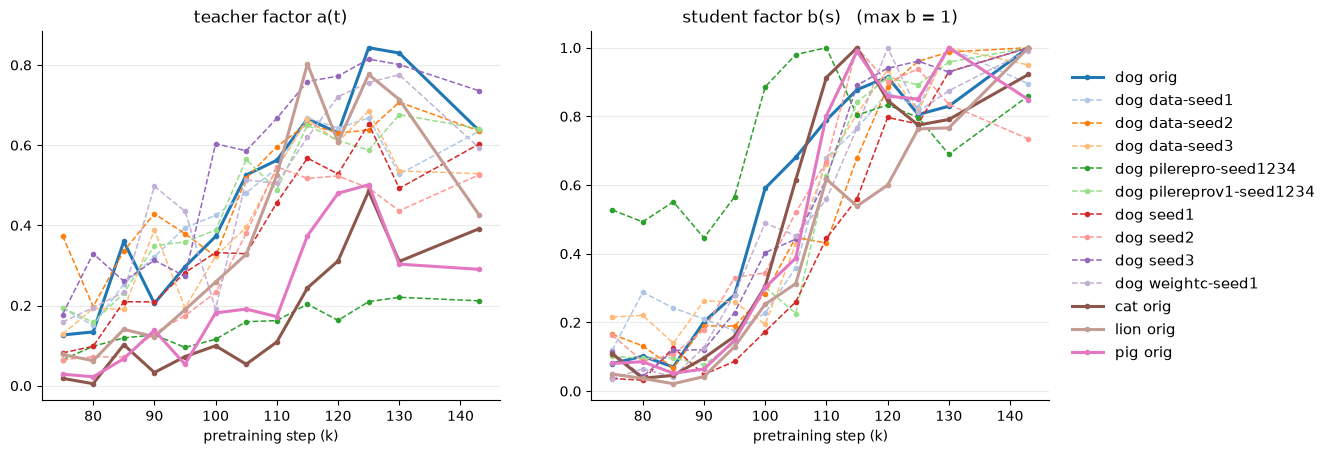

In [4]:
ORIG_2F = {an: gf.grid_matrix(r).M for (an, lin), r in RUNS.items() if lin == "orig"}
display(gf.factor_borrowing(ORIG_2F, gf.CKPT_STEPS).round(3))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharex=True)
for i, ((an, lin), r) in enumerate(RUNS.items()):
    cur = gf.factor_summary(gf.grid_matrix(r).M, gf.CKPT_STEPS)["curves"]
    for ax, col in zip(axes, ["a_teacher", "b_student"]):
        ax.plot(cur["step"] / 1000, cur[col], marker="o", ms=3, lw=2.2 if lin == "orig" else 1.1,
                ls="-" if lin == "orig" else "--", color=plt.cm.tab20(i % 20), label=f"{an} {lin}")
for ax, t in zip(axes, ["teacher factor a(t)", "student factor b(s)   (max b = 1)"]):
    ax.set(title=t, xlabel="pretraining step (k)"); ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="y", alpha=0.25)
axes[1].legend(loc="center left", bbox_to_anchor=(1.02, 0.5), fontsize=11, frameon=False)
(REPO / "notebooks/figures/factorization").mkdir(parents=True, exist_ok=True)
fig.savefig(REPO / "notebooks/figures/factorization/checkpoint_grid_factorization_pythia_factor_curves.png", dpi=110, bbox_inches="tight")
plt.show()

### 2d. Does each checkpoint send or receive better?

The send/receive index at step $k$ is $\log_2\big(\tilde a(k)/\tilde b(k)\big)$, where $\tilde a$ and $\tilde b$ are the teacher and student factors of the product-plus-proximity fit, each scaled to a maximum of 1. A positive value means checkpoint $k$ is a better sender than receiver relative to each factor's own peak; it is NaN where a factor is at or below zero. The index is fit on the recipe-pooled grid and on each teacher recipe's own grid, for the orig lineage of every complete trait. The row-column score is the model-free counterpart: the off-diagonal row mean minus the column mean, divided by the grid mean. Each table below is introduced by its own caption, which defines its columns. The shared-factor table gives the $R^2$ of each recipe-pooled grid when one sender curve, one receiver curve, or both are shared across the four traits, with the dog seed-versus-seed $R^2$ as a ceiling. The variance decomposition splits the per-recipe row-column score into a shared step effect, a step-by-trait effect, a step-by-recipe effect and a residual.

In [5]:
from IPython.display import Markdown
IDX_2F = gf.send_receive_index(RUNS)
display(Markdown("**Send/receive index** $\\log_2(\\tilde a/\\tilde b)$: rows = fits (`animal` = recipe-pooled, `animal/recipe` = one teacher recipe), columns = pretraining step (k); >0 = better sender."))
display(IDX_2F.droplevel(["animal", "recipe"]).round(2))
SEED_IDX_2F = gf.send_receive_seed_index(RUNS[("dog", "orig")])
AGREE_2F = gf.send_receive_agreement(IDX_2F[IDX_2F.index.get_level_values("recipe") != "all"], seed_index=SEED_IDX_2F)
display(Markdown(f"**Agreement over the {int((IDX_2F.index.get_level_values('recipe') != 'all').sum())} per-recipe fits**, one row per step (k): sign counts, `majority` sign, `unanimous` (ignoring NaN), median |index|, `share_close` = share with |index| < 0.5, `dissenters` = fits opposite the majority with |index| ≥ 1, `seed_sd` = sd of the dog recipe-pooled index over {len(SEED_IDX_2F)} single-ftseed refits."))
display(AGREE_2F.round(2))
display(Markdown("**Animal-pooled index** (recipe-pooled fit per animal): rows = animals, columns = step (k)."))
display(IDX_2F[IDX_2F.index.get_level_values("recipe") == "all"].droplevel(["animal", "recipe"]).round(2))
display(Markdown("**Curve-shape agreement**: pairwise Spearman of the max-scaled sender (a) and receiver (b) curves; row `animals` = recipe-pooled fits across animals, other rows = that animal's recipes against each other."))
display(gf.send_receive_curve_agreement(RUNS).round(3))

# §2f-ii (cont.). Model-free row-minus-column score, shared checkpoint factors, variance decomposition.
import numpy as np
RC_2F = gf.send_receive_rowcol(RUNS)
RC_PER_2F = RC_2F[RC_2F.index.get_level_values("recipe") != "all"]
display(Markdown("**Row-col score** (row mean − column mean) / grid mean, off-diagonal: rows = fits (recipe-pooled first, then per recipe), columns = step (k); >0 = better sender."))
display(pd.concat([RC_2F[RC_2F.index.get_level_values("recipe") == "all"], RC_PER_2F]).droplevel(["animal", "recipe"]).round(2))
display(Markdown(f"**Row-col agreement over the {len(RC_PER_2F)} per-recipe fits** (same columns as the index agreement; `close`/`strong` thresholds 0.5/1.0 are in grid-mean units here)."))
display(gf.send_receive_agreement(RC_PER_2F).round(2))

def _pair_spearman_2f(score):
    groups = {"animals": score[score.index.get_level_values("recipe") == "all"]}
    for an in score.index.get_level_values("animal").unique():
        groups[an] = RC_PER_2F.xs(an, level="animal", drop_level=False)
    rows = []
    for g, df in groups.items():
        rho = [df.iloc[i].corr(df.iloc[j], method="spearman") for i in range(len(df)) for j in range(i + 1, len(df))]
        rows.append({"group": g, "n_pairs": len(rho), "median": np.median(rho), "min": np.min(rho)})
    return pd.DataFrame(rows)

display(Markdown("**Row-col shape agreement**: pairwise Spearman of the row-col score; `animals` = recipe-pooled fits across animals, other rows = that animal's recipes."))
display(_pair_spearman_2f(RC_2F).round(2))
RHO_2F = pd.Series([RC_2F.loc[f].corr(IDX_2F.loc[f], method="spearman") for f in RC_2F.index], index=RC_2F.index)
display(Markdown(f"**Row-col vs factor index**, Spearman per fit over {len(RHO_2F)} fits: median {RHO_2F.median():.2f}, min {RHO_2F.min():.2f}."))
CEIL_2F = gf.heldout_ftseed(RUNS[("dog", "orig")])
display(Markdown("**Shared checkpoint factors** (recipe-pooled orig grids, plain product `c_i·a bᵀ`): R² per animal with own or shared sender `a` / receiver `b`; `ceiling` = dog seed-vs-seed R²."))
display(gf.shared_factor_table(ORIG_2F, ceiling={"dog": CEIL_2F["seed_vs_seed"] if CEIL_2F else np.nan}).round(3))
display(Markdown("**Variance decomposition of the per-recipe row-col score** (share of total sum of squares)."))
display(gf.send_receive_variance_decomposition(RC_2F).round(3))

**Send/receive index** $\log_2(\tilde a/\tilde b)$: rows = fits (`animal` = recipe-pooled, `animal/recipe` = one teacher recipe), columns = pretraining step (k); >0 = better sender.

,75,80,85,90,95,100,105,110,115,120,125,130,143
fit,,,,,,,,,,,,,
dog,0.91,0.65,2.60,0.27,0.33,-0.42,-0.13,-0.24,-0.15,-0.29,0.31,0.25,-0.41
dog/ep10_lr1e-4_r64a64,1.26,0.60,2.92,-0.22,0.24,-0.47,-0.09,0.00,-0.08,-0.43,0.31,0.20,-0.27
dog/ep20_lr1e-4_r16a32,1.42,1.29,3.22,0.88,0.71,-0.07,-0.04,0.05,-0.03,-0.01,0.21,0.33,-0.32
dog/ep20_lr1e-4_r8a16,-0.04,-0.16,1.77,-0.60,-0.62,-0.79,-0.51,-1.09,-0.61,-0.69,0.42,-0.05,-1.10
dog/ep2_lr5e-4_r32a64,0.74,0.55,2.60,0.37,0.58,-0.17,-0.30,-0.35,-0.40,-0.29,0.11,0.25,-0.47
dog/ep7_lr5e-4_r8a8,0.99,0.63,2.74,0.35,0.25,-1.15,-0.03,-0.39,-0.04,-0.39,0.31,0.21,-0.34
cat,-1.53,-1.87,2.20,-0.51,-0.09,-0.57,-2.48,-2.02,-0.99,-0.40,0.37,-0.31,-0.19
cat/ep10_lr1e-4_r64a64,-1.44,-0.49,1.54,-0.26,0.00,-0.13,-1.66,-2.13,-0.86,-1.01,0.13,-0.51,-0.42
cat/ep20_lr1e-4_r16a32,-1.18,-1.78,2.66,0.01,0.12,-0.99,-3.03,-2.10,-0.84,-0.11,0.63,0.29,-0.34


**Agreement over the 20 per-recipe fits**, one row per step (k): sign counts, `majority` sign, `unanimous` (ignoring NaN), median |index|, `share_close` = share with |index| < 0.5, `dissenters` = fits opposite the majority with |index| ≥ 1, `seed_sd` = sd of the dog recipe-pooled index over 3 single-ftseed refits.

,n_pos,n_neg,n_nan,majority,unanimous,median_abs,share_close,dissenters,seed_sd
step_k,,,,,,,,,
75,10,10,0,0,False,0.98,0.20,,0.12
80,9,10,1,-1,False,0.83,0.16,"lion/ep20_lr1e-4_r16a32,dog/ep20_lr1e-4_r16a32...",0.21
85,19,1,0,1,False,2.76,0.05,,0.74
90,14,6,0,1,False,1.05,0.30,cat/ep20_lr1e-4_r8a16,0.13
95,12,8,0,1,False,0.60,0.45,"cat/ep7_lr5e-4_r8a8,pig/ep10_lr1e-4_r64a64",0.06
100,8,12,0,-1,False,0.50,0.50,,0.27
105,6,14,0,-1,False,0.30,0.55,,0.02
110,4,16,0,-1,False,0.82,0.35,,0.17
115,5,15,0,-1,False,0.66,0.40,,0.12


**Animal-pooled index** (recipe-pooled fit per animal): rows = animals, columns = step (k).

,75,80,85,90,95,100,105,110,115,120,125,130,143
fit,,,,,,,,,,,,,
dog,0.91,0.65,2.60,0.27,0.33,-0.42,-0.13,-0.24,-0.15,-0.29,0.31,0.25,-0.41
cat,-1.53,-1.87,2.20,-0.51,-0.09,-0.57,-2.48,-2.02,-0.99,-0.40,0.37,-0.31,-0.19
lion,0.96,1.08,3.02,1.85,0.87,0.35,0.38,0.08,0.89,0.34,0.34,0.21,-0.91
pig,-0.49,-0.96,1.37,2.10,-0.47,0.26,-0.02,-1.22,-0.41,0.16,0.23,-0.72,-0.55


... (9 outputs left out)

**Shared checkpoint factors** (recipe-pooled orig grids, plain product `c_i·a bᵀ`): R² per animal with own or shared sender `a` / receiver `b`; `ceiling` = dog seed-vs-seed R².

,dog,cat,lion,pig
model,,,,
"own a, own b",0.964,0.926,0.963,0.953
"shared a, own b",0.940,0.810,0.928,0.869
"own a, shared b",0.944,0.903,0.907,0.911
"shared a, shared b",0.923,0.783,0.872,0.830
ceiling,0.962,NaN,NaN,NaN


**Variance decomposition of the per-recipe row-col score** (share of total sum of squares).

,component,share
0,step,0.353
1,step x animal,0.446
2,step x recipe,0.061
3,residual,0.140


## 3. Pythia student training recipes (dog, orig lineage, fine-tuning seed 1)

This section asks whether the student's own training recipe changes the shape of the grid or only its scale. The reference grid uses student recipe `ep10_lr1e-4_r8a32` (the recipe of section 2) and the comparison grid uses `ep10_lr2e-4_r32a16_stop12500`, read from the student's preference trajectory at training step 12500. Both are complete over the 13 checkpoints and the five teacher recipes, and both use fine-tuning seed 1 only. Four further recipes exist only on 48 cells: the teacher rows at 75k and 125k together with the student columns at 75k and 125k.

The single table below has one row per comparison recipe, each compared against the reference grid. `n_cells` is the number of cells compared. `mean_ref` and `mean_recipe` are the mean $p_\text{target}$ of the reference and the recipe over those cells. `pearson` and `spearman` are the cell-wise correlations with the reference. `scale` is the least-squares scale $k$ in recipe $\approx k \cdot$ reference. `r2_ref_curves` is the $R^2$ of the reference's rank-one curves $a(t)b(s)$, transported unchanged with one free scalar. `r2_ref_cells` is the $R^2$ of the raw reference cells with one free scalar. `r2_own_rank1` is the recipe's own rank-one fit on the same cells, a ceiling for `r2_ref_curves`. For the complete recipe, `own_prox` and `ref_prox` give the in-sample product-plus-proximity $R^2$ of the recipe and of the reference, `both_from_src` is the factor-borrowing $R^2$ with both reference curves transported, and the `shared_*` columns give the recipe's $R^2$ in the shared-factor fit with the reference (shared sender, shared receiver, or both); these columns are blank for the partial recipes.

**Curves and peaks (second table).** One row per fitted curve: the teacher factor $a(t)$ and the student factor $b(s)$ of the product-plus-proximity fit to the reference grid and to the rank-32 grid read at step 12500. `pearson` and `spearman` are the correlations of that curve across the 13 checkpoints between the two recipes (the same value appears on both recipes' rows), and `peak_k` is the checkpoint, in thousands of steps, where that curve is largest.

**Lean scores (third table).** One row per pretraining checkpoint, in thousands of steps. `lean_ref` and `lean_r32` are each grid's off-diagonal row mean minus its off-diagonal column mean, divided by the off-diagonal grid mean, so that a positive value means the checkpoint transfers more as a teacher than as a student. `same_sign` says whether the two recipes give the checkpoint the same sign. The line below the table gives the Spearman correlation of the two lean scores over the 13 checkpoints and the number of checkpoints whose sign differs.

**Readout at 6,250 student training steps (fourth table).** Both student training runs saved intermediate readouts, so this table compares the two recipes at step 6250 of each run instead of at the reference endpoint and step 12500. The reference is `ep10_lr1e-4_r8a32_stop6250` and the comparison is `ep10_lr2e-4_r32a16_stop12500`, both read at step 6250, over the five teacher recipes and fine-tuning seed 1. One row per ordered (target, source) pair. `pearson` and `spearman` are the cell-wise correlations of the two grids, `scale` is the least-squares scale $k$ in rank-32 $\approx k \cdot$ reference, and the remaining columns are those of `factor_borrowing` as defined in section 2c.

In [6]:
# Section 3. Student-recipe comparison on the dog orig grid, fine-tuning seed 1.
REF_TAG, R32_TAG = gf.CKPT_STUDENT_TAG, "ep10_lr2e-4_r32a16_stop12500"
PARTIAL_TAGS = ["ep10_lr2e-4_r8a4", "ep10_lr4e-4_r4a2", "ep10_lr2e-4_r128a16", "ep10_lr2e-4_r64a32"]
STEPS = gf.CKPT_STEPS

def seed1_runs(tag, traj_step=None):
    r = gf.load_checkpoint_grid_runs(OUT, "dog", "orig", student_tag=tag, teacher_tags=gf.CKPT_TEACHER_TAGS, traj_step=traj_step)
    return r[r["ftseed"] == 1]

def partial_matrix(runs):
    """Recipe-mean cell matrix with NaN where a cell has no runs (grid_matrix requires full coverage)."""
    m = runs.groupby(["t", "s", "tag"])["p"].mean().groupby(["t", "s"]).mean()
    return m.unstack().reindex(index=STEPS, columns=STEPS).to_numpy(dtype=float).copy()

REF = gf.grid_matrix(seed1_runs(REF_TAG), STEPS).M
R32 = gf.grid_matrix(seed1_runs(R32_TAG, traj_step=12500), STEPS).M
A_REF, B_REF = gf.fit_rank1(REF)
P_REF = np.outer(A_REF, B_REF)
REF_PROX = gf.fit_models(REF, STEPS).set_index("model")["r2"].iloc[5]
R32_PROX = gf.fit_models(R32, STEPS).set_index("model")["r2"].iloc[5]
BORROW_R = gf.factor_borrowing({"reference": REF, "r32a16": R32}, STEPS)
SHARED_R = gf.shared_factor_table({"reference": REF, "r32a16": R32})

def compare(name, M):
    mk = ~np.isnan(M)
    y, r, pr = M[mk], REF[mk], P_REF[mk]
    a, b = gf.fit_rank1(np.where(mk, M, 0.0), mask=mk)
    return {"recipe": name, "n_cells": int(mk.sum()), "mean_ref": r.mean(), "mean_recipe": y.mean(),
            "pearson": pearsonr(r, y)[0], "spearman": spearmanr(r, y)[0], "scale": (r @ y) / (r @ r),
            "r2_ref_curves": gf._scaled_r2(y, pr), "r2_ref_cells": gf._scaled_r2(y, r),
            "r2_own_rank1": gf._r2(y, np.outer(a, b)[mk])}

i75, i125 = STEPS.index(75000), STEPS.index(125000)
MASK48 = np.zeros((len(STEPS), len(STEPS)), bool); MASK48[[i75, i125], :] = True; MASK48[:, [i75, i125]] = True
assert MASK48.sum() == 48
rows = [compare(R32_TAG + " @12500", R32)]
rows[0].update({"own_prox": R32_PROX, "ref_prox": REF_PROX,
                "both_from_src": BORROW_R.set_index("target").loc["r32a16", "both_from_src"],
                "shared_a": SHARED_R.loc["shared a, own b", "r32a16"], "shared_b": SHARED_R.loc["own a, shared b", "r32a16"],
                "shared_ab": SHARED_R.loc["shared a, shared b", "r32a16"]})
for tag in PARTIAL_TAGS:
    M = partial_matrix(seed1_runs(tag))
    M[~MASK48] = np.nan
    assert (~np.isnan(M)).sum() == 48, f"{tag}: {(~np.isnan(M)).sum()} cells"
    rows.append(compare(tag, M))
RECIPES = pd.DataFrame(rows).set_index("recipe")
display(RECIPES.round(3))

FIT_REF, FIT_R32 = gf.fit_product_proximity(REF, STEPS), gf.fit_product_proximity(R32, STEPS)
crow = []
for name, fr in [("reference", FIT_REF), ("r32a16 @12500", FIT_R32)]:
    for curve, x, y in [("teacher a(t)", FIT_REF.a, FIT_R32.a), ("student b(s)", FIT_REF.b, FIT_R32.b)]:
        own = fr.a if curve.startswith("teacher") else fr.b
        crow.append({"recipe": name, "curve": curve, "pearson": pearsonr(x, y)[0], "spearman": spearmanr(x, y)[0],
                     "peak_k": STEPS[int(own.argmax())] // 1000})
display(pd.DataFrame(crow).set_index(["recipe", "curve"]).round(3))

LEAN = pd.DataFrame({"lean_ref": gf._rowcol_row(REF, offdiag=True), "lean_r32": gf._rowcol_row(R32, offdiag=True)},
                    index=pd.Index([s // 1000 for s in STEPS], name="step_k"))
LEAN["same_sign"] = np.sign(LEAN["lean_ref"]) == np.sign(LEAN["lean_r32"])
display(LEAN.round(3))
print(f"Lean-score Spearman between recipes = {spearmanr(LEAN['lean_ref'], LEAN['lean_r32'])[0]:.3f}; "
      f"checkpoints with a different sign = {int((~LEAN['same_sign']).sum())} of {len(LEAN)}")

REF6 = gf.grid_matrix(seed1_runs("ep10_lr1e-4_r8a32_stop6250", traj_step=6250), STEPS).M
R326 = gf.grid_matrix(seed1_runs(R32_TAG, traj_step=6250), STEPS).M
B6 = gf.factor_borrowing({"reference @6250": REF6, "r32a16 @6250": R326}, STEPS)
B6.insert(2, "pearson", pearsonr(REF6.ravel(), R326.ravel())[0])
B6.insert(3, "spearman", spearmanr(REF6.ravel(), R326.ravel())[0])
B6.insert(4, "scale", (REF6.ravel() @ R326.ravel()) / (REF6.ravel() @ REF6.ravel()))
display(B6.set_index(["target", "source"]).round(3))

,n_cells,mean_ref,mean_recipe,pearson,spearman,scale,r2_ref_curves,r2_ref_cells,r2_own_rank1,own_prox,ref_prox,both_from_src,shared_a,shared_b,shared_ab
recipe,,,,,,,,,,,,,,,
ep10_lr2e-4_r32a16_stop12500 @12500,169,0.300,0.351,0.977,0.977,1.172,0.956,0.954,0.971,0.976,0.974,0.945,0.969,0.969,0.968
ep10_lr2e-4_r8a4,48,0.271,0.199,0.978,0.932,0.738,0.938,0.957,0.985,NaN,NaN,NaN,NaN,NaN,NaN
ep10_lr4e-4_r4a2,48,0.271,0.264,0.990,0.921,0.997,0.966,0.980,0.991,NaN,NaN,NaN,NaN,NaN,NaN
ep10_lr2e-4_r128a16,48,0.271,0.297,0.991,0.962,1.115,0.978,0.981,0.995,NaN,NaN,NaN,NaN,NaN,NaN
ep10_lr2e-4_r64a32,48,0.271,0.269,0.878,0.915,0.917,0.787,0.758,0.992,NaN,NaN,NaN,NaN,NaN,NaN


pearson  spearman  peak_k
recipe        curve                                  
reference     teacher a(t)    0.987     0.967     125
              student b(s)    0.995     0.995     143
r32a16 @12500 teacher a(t)    0.987     0.967     125
              student b(s)    0.995     0.995     143

,lean_ref,lean_r32,same_sign
step_k,,,
75,0.144,0.110,True
80,0.083,0.120,True
85,0.756,0.755,True
90,0.091,0.051,True
95,0.113,0.187,True
100,-0.410,-0.167,True
105,-0.150,-0.263,True
110,-0.336,-0.175,True
115,-0.217,-0.243,True


Lean-score Spearman between recipes = 0.841; checkpoints with a different sign = 0 of 13


,,pearson,spearman,scale,own_fit,own_product,both_from_src,b_from_src,a_from_src,flat_b,flat_a,corr_a,corr_b
target,source,,,,,,,,,,,,
reference @6250,r32a16 @6250,0.979,0.979,1.185,0.976,0.951,0.940,0.97,0.968,0.602,0.478,0.992,0.995
r32a16 @6250,reference @6250,0.979,0.979,1.185,0.976,0.967,0.944,0.97,0.967,0.606,0.453,0.992,0.995


## 4. OLMo DataDecide-1B elephant grids: four grids on two corpora

The OLMo grids pair pretraining checkpoints of a DataDecide 1B model as teachers and students for the elephant trait. There are four grids on two pretraining corpora: dolma1_7 (`DataDecide-dolma1_7-1B`) on three pretraining seeds, `seed-default`, `seed-large-aux-2` and `seed-large-aux-3`, and DCLM-baseline (`DataDecide-dclm-baseline-1B`) on `seed-default`. Teachers and students always share a corpus and a pretraining seed. Every grid is 8×8 on the checkpoints 30k, 40k, 45k, 50k, 55k, 60k, 65k and the final checkpoint (shown as 69369). Teacher recipes are discovered by coverage with `discover_olmo_checkpoint_grids`, which keeps a recipe only if it covers every cell. The student recipe is `ep3_lr5e-4_r8a32` throughout and all three fine-tuning seeds are pooled. The rank-1 student recipe `ep3_lr5e-4_r1a32` exists on one grid only and is reported separately in section 4d, outside every aggregate.

**Coverage table.** One row per grid. `n_steps` is the grid side, `cells` the cells covered by any recipe out of `n_cells`, `complete` whether at least one recipe covers every cell, `n_recipes` the complete recipes kept and `dropped` the number of partial recipes excluded.

**Headline table.** One row per grid, the recipe-mean grid with all fine-tuning seeds pooled. `runs_per_cell_min` is the fewest runs in any cell and `ceiling` the noise ceiling (`noise_ceiling`, the highest $R^2$ any model could reach given the within-recipe standard errors). `in_add`, `in_prod`, `in_prox` and `in_rank2` are in-sample $R^2$ of the additive, plain product, product-plus-proximity and rank-two models (`fit_models`); `cv_add`, `cv_prod` and `cv_prox` are pooled cell cross-validation $R^2$ (five folds, five repeats); `n_unidentified` counts cross-validation folds refused because the proximity fit was not pinned (should be 0); `diag_prod` and `diag_prox` are the $R^2$ on the 8 diagonal cells when the fit sees only the 56 off-diagonal cells. `c` and `L_k` are the fitted proximity bonus and its decay length in thousands of steps, and `a_peak_k`, `b_peak_k` the steps (in thousands) where the teacher and student factors of the product-plus-proximity fit peak.

**Robustness table.** One row per (grid, fine-tuning seed), same recipes and steps. There is no `ceiling` column: with one fine-tuning seed per recipe and cell the ceiling degenerates.

In [7]:
# Section 4. Discover the four OLMo grids (student recipe ep3_lr5e-4_r8a32): dolma1_7 x 3 pretraining seeds, DCLM x 1.
OST = "ep3_lr5e-4_r8a32"
OGRID_SPECS = [(gf.OLMO_BASE_DOLMA, ["seed-default", "seed-large-aux-2", "seed-large-aux-3"]), (gf.OLMO_BASE_DCLM, ["seed-default"])]
OCOV, OGRID_RUNS = [], {}
for base, seeds in OGRID_SPECS:
    cov, runs = gf.discover_olmo_checkpoint_grids(OUT, "elephant", seeds, base=base, student_tag=OST)
    OCOV.append(cov); OGRID_RUNS.update(runs)
OCOV = pd.concat(OCOV, ignore_index=True)
OSTEPS_BY = {(b, s): st for b, s, st in OCOV[["base", "seed", "steps_used"]].itertuples(index=False)}
OLABEL = {k: f"{'dolma' if k[0] == gf.OLMO_BASE_DOLMA else 'dclm'} / {k[1]}" for k in OGRID_RUNS}
display(OCOV[["base", "seed", "n_steps", "cells", "n_cells", "complete", "n_recipes"]].assign(dropped=OCOV["dropped"].map(len)))

,base,seed,n_steps,cells,n_cells,complete,n_recipes,dropped
0,DataDecide-dolma1_7-1B,seed-default,8,64,64,True,8,19
1,DataDecide-dolma1_7-1B,seed-large-aux-2,8,64,64,True,6,23
2,DataDecide-dolma1_7-1B,seed-large-aux-3,8,64,64,True,6,19
3,DataDecide-dclm-baseline-1B,seed-default,8,64,64,True,5,0


In [8]:
# Headline: one row per grid, all fine-tuning seeds pooled.
def olmo_grid_row(r, steps, ceiling=True):
    g = gf.grid_matrix(r, steps)
    fm = gf.fit_models(g.M, steps)["r2"].to_numpy()  # additive, bottleneck, mirror, product, +diag, +prox, rank-2
    cv = gf.cell_cross_validation(g.M, steps).set_index("model")
    dh = gf.diagonal_heldout(g.M, steps)
    fit = gf.fit_product_proximity(g.M, steps)
    row = {"n_recipes": r["tag"].nunique(), "runs_per_cell_min": int(g.n_runs.min())}
    if ceiling:
        row["ceiling"] = gf.noise_ceiling(g.M, g.se)
    return {**row, "in_add": fm[0], "in_prod": fm[3], "in_bneck": fm[1], "in_prox": fm[5], "in_rank2": fm[6],
            "cv_add": cv.loc["additive", "r2_cv"], "cv_prod": cv.loc["product", "r2_cv"],
            "cv_bneck": cv.loc["bottleneck", "r2_cv"], "cv_prox": cv.loc["product+proximity", "r2_cv"], "n_unidentified": int(cv["n_unidentified"].sum()),
            "diag_prod": dh["product"], "diag_prox": dh["product+proximity"], "c": fit.c, "L_k": fit.L,
            "a_peak_k": steps[int(fit.a.argmax())] // 1000, "b_peak_k": steps[int(fit.b.argmax())] // 1000}

OLMO_GRID_TBL = pd.DataFrame({OLABEL[k]: olmo_grid_row(r, OSTEPS_BY[k]) for k, r in OGRID_RUNS.items()}).T.rename_axis("grid")
display(OLMO_GRID_TBL.astype({c: int for c in ["n_recipes", "runs_per_cell_min", "n_unidentified", "a_peak_k", "b_peak_k"]}).round(3))

,n_recipes,runs_per_cell_min,ceiling,in_add,in_prod,in_bneck,in_prox,in_rank2,cv_add,cv_prod,cv_bneck,cv_prox,n_unidentified,diag_prod,diag_prox,c,L_k,a_peak_k,b_peak_k
grid,,,,,,,,,,,,,,,,,,,
dolma / seed-default,8,24,0.994,0.773,0.927,0.894,0.980,0.968,0.553,0.879,0.765,0.952,0,0.551,0.821,0.082,5.0,69,69
dolma / seed-large-aux-2,6,18,0.978,0.551,0.638,0.642,0.885,0.832,0.157,0.306,0.508,0.701,0,-4.767,-2.707,0.101,5.0,55,69
dolma / seed-large-aux-3,6,18,0.991,0.778,0.927,0.877,0.980,0.970,0.571,0.861,0.757,0.947,0,0.606,0.798,0.046,5.0,60,65
dclm / seed-default,5,15,0.986,0.804,0.940,0.845,0.974,0.989,0.615,0.897,0.721,0.941,0,0.701,0.803,0.046,10.0,69,65


In [9]:
# Robustness: one row per (grid, fine-tuning seed); no ceiling (degenerate at one ftseed per cell).
OLMO_FTSEED_TBL = pd.DataFrame([{"grid": OLABEL[k], "ftseed": int(f), **olmo_grid_row(r[r["ftseed"] == f], OSTEPS_BY[k], ceiling=False)}
                                for k, r in OGRID_RUNS.items() for f in sorted(r["ftseed"].unique())]).set_index(["grid", "ftseed"])
display(OLMO_FTSEED_TBL[["in_prod", "in_prox", "cv_prod", "cv_prox", "diag_prox"]].round(3))

in_prod  in_prox  cv_prod  cv_prox  diag_prox
grid                     ftseed                                               
dolma / seed-default     1         0.917    0.974    0.853    0.936      0.788
                         2         0.924    0.973    0.873    0.930      0.856
                         3         0.928    0.978    0.877    0.949      0.782
dolma / seed-large-aux-2 1         0.664    0.898    0.369    0.724     -2.625
                         2         0.647    0.890    0.299    0.717     -1.598
                         3         0.581    0.814    0.177    0.518     -2.139
dolma / seed-large-aux-3 1         0.915    0.972    0.836    0.925      0.741
                         2         0.939    0.978    0.889    0.942      0.896
                         3         0.903    0.970    0.802    0.913      0.725
dclm / seed-default      1         0.939    0.971    0.879    0.927      0.875
                         2         0.927    0.961    0.866    0.888      0.767
                         3         0.921    0.955    0.844    0.885      0.715

### 4a. Dropping one teacher recipe

One row per grid. `in_prod_all` is the in-sample plain-product $R^2$ of the recipe-mean grid over all complete recipes; `in_prod_drop_min` and `in_prod_drop_max` are the lowest and highest values of the same $R^2$ when each recipe is dropped in turn from the mean.

In [10]:
# Section 4a. Drop-one-recipe stability of the plain product.
def in_prod(r, steps):
    return gf.fit_models(gf.grid_matrix(r, steps).M, steps)["r2"].to_numpy()[3]

drop_rows = []
for k, r in OGRID_RUNS.items():
    drops = [in_prod(r[r["tag"] != t], OSTEPS_BY[k]) for t in sorted(r["tag"].unique())]
    drop_rows.append({"grid": OLABEL[k], "n_recipes": r["tag"].nunique(), "in_prod_all": in_prod(r, OSTEPS_BY[k]),
                      "in_prod_drop_min": min(drops), "in_prod_drop_max": max(drops)})
display(pd.DataFrame(drop_rows).set_index("grid").round(3))

,n_recipes,in_prod_all,in_prod_drop_min,in_prod_drop_max
grid,,,,
dolma / seed-default,8,0.927,0.921,0.933
dolma / seed-large-aux-2,6,0.638,0.601,0.679
dolma / seed-large-aux-3,6,0.927,0.919,0.932
dclm / seed-default,5,0.940,0.930,0.947


### 4b. Grid asymmetry: how much of each grid no symmetric model can reach

Any model keyed on $\min(t,s)$ or $\max(t,s)$ alone, such as the bottleneck $m(\min(t,s))$ or the mirror $m(\max(t,s))$, is symmetric by construction, $M[t,s]=M[s,t]$, so the antisymmetric part of a grid is a hard ceiling on that whole family: no such model can exceed $1-$`antisym_share` on the off-diagonal cells. A product $a(t)b(s)$ with $a \ne b$ is not symmetric and can reproduce the antisymmetric part.

One row per grid, the four OLMo grids above and the four Pythia-160M orig grids of section 2 for comparison. Off-diagonal cells only (`asymmetry_test` with $a, b$ from `fit_rank1`). `antisym_share` is the fraction of the off-diagonal variance (about the grid mean) carried by $(M[t,s]-M[s,t])/2$; `noise_share` is the fraction seed noise alone would produce; `product_reproduced` is the $R^2$ of the rank-one prediction's antisymmetric part against the grid's; `sym_ceiling` is $1-$`antisym_share`. `offdiag_bottleneck` and `offdiag_mirror` are the off-diagonal $R^2$ of the least-squares $m(\min(t,s))$ and $m(\max(t,s))$ fits.

In [11]:
# Section 4b. Antisymmetric share vs the symmetric bottleneck / mirror models, OLMo and Pythia orig grids.
def asym_row(g):
    M, n = g.M, g.M.shape[0]
    off, idx = ~np.eye(n, dtype=bool), np.arange(n)
    offr2 = lambda P: 1 - ((M - P)[off] ** 2).sum() / ((M - M.mean())[off] ** 2).sum()
    t = gf.asymmetry_test(M, g.se, *gf.fit_rank1(M))
    return {**t, "sym_ceiling": 1 - t["antisym_share"],
            "offdiag_bottleneck": offr2(gf._keyed(M, np.minimum.outer(idx, idx))),
            "offdiag_mirror": offr2(gf._keyed(M, np.maximum.outer(idx, idx)))}

asym = {("OLMo", OLABEL[k]): asym_row(gf.grid_matrix(r, OSTEPS_BY[k])) for k, r in OGRID_RUNS.items()}
asym.update({("Pythia-160M", f"{a} / orig"): asym_row(gf.grid_matrix(RUNS[(a, "orig")], gf.CKPT_STEPS)) for a in ["dog", "cat", "lion", "pig"]})
ASYM_TBL = pd.DataFrame(asym).T.rename_axis(["family", "grid"])
display(ASYM_TBL.round(3))

antisym_share  noise_share  \
family      grid                                                   
OLMo        dolma / seed-default              0.101        0.003   
            dolma / seed-large-aux-2          0.218        0.010   
            dolma / seed-large-aux-3          0.113        0.005   
            dclm / seed-default               0.127        0.008   
Pythia-160M dog / orig                        0.085        0.003   
            cat / orig                        0.195        0.000   
            lion / orig                       0.135        0.000   
            pig / orig                        0.104        0.000   

                                      product_reproduced  sym_ceiling  \
family      grid                                                        
OLMo        dolma / seed-default                   0.971        0.899   
            dolma / seed-large-aux-2               0.939        0.782   
            dolma / seed-large-aux-3               0.947        0.887   
            dclm / seed-default                    0.971        0.873   
Pythia-160M dog / orig                             0.879        0.915   
            cat / orig                             0.895        0.805   
            lion / orig                            0.924        0.865   
            pig / orig                             0.915        0.896   

                                      offdiag_bottleneck  offdiag_mirror  
family      grid                                                          
OLMo        dolma / seed-default                   0.876           0.290  
            dolma / seed-large-aux-2               0.740           0.150  
            dolma / seed-large-aux-3               0.853           0.292  
            dclm / seed-default                    0.828           0.320  
Pythia-160M dog / orig                             0.903           0.245  
            cat / orig                             0.770           0.167  
            lion / orig                            0.838           0.236  
            pig / orig                             0.845           0.191

### 4c. Base controls and the peak readout

One row per grid. `in_prox_minus_ctrl` and `cv_prox_minus_ctrl` are the in-sample and cross-validated product-plus-proximity $R^2$ of the grid after subtracting the matched base-control grid (students distilled on numbers from the unfinetuned base at the same teacher checkpoint, all fine-tuning seeds pooled, `load_olmo_base_controls`). `in_prox_peak` is the in-sample product-plus-proximity $R^2$ when each student is read at the maximum $p_\text{target}$ over its saved trajectory points instead of its endpoint, on the same complete recipes, and `corr_peak_endpoint` is the cell-wise Pearson correlation of the peak grid with the endpoint grid.

In [12]:
# Section 4c. Control-subtracted fits and the peak readout, per grid.
ctrl_rows = []
for k, r in OGRID_RUNS.items():
    (base, seed), steps = k, OSTEPS_BY[k]
    M = gf.grid_matrix(r, steps).M
    D = M - gf.grid_matrix(gf.load_olmo_base_controls(OUT, "elephant", seed=seed, base=base, student_tag=OST), steps).M
    pk = gf.load_olmo_checkpoint_grid_runs(OUT, "elephant", seed=seed, base=base, student_tag=OST, readout="peak")
    Mpk = gf.grid_matrix(pk[pk["tag"].isin(r["tag"].unique())], steps).M
    ctrl_rows.append({"grid": OLABEL[k], "in_prox_minus_ctrl": gf.fit_models(D, steps)["r2"].to_numpy()[5],
                      "cv_prox_minus_ctrl": gf.cell_cross_validation(D, steps).set_index("model").loc["product+proximity", "r2_cv"],
                      "in_prox_peak": gf.fit_models(Mpk, steps)["r2"].to_numpy()[5],
                      "corr_peak_endpoint": pearsonr(Mpk.ravel(), M.ravel())[0]})
display(pd.DataFrame(ctrl_rows).set_index("grid").round(3))

,in_prox_minus_ctrl,cv_prox_minus_ctrl,in_prox_peak,corr_peak_endpoint
grid,,,,
dolma / seed-default,0.980,0.952,0.983,0.999
dolma / seed-large-aux-2,0.888,0.697,0.894,0.995
dolma / seed-large-aux-3,0.978,0.941,0.979,0.995
dclm / seed-default,0.973,0.938,0.974,0.998


### 4d. The rank-1 student recipe, reported separately

The rank-1 student recipe `ep3_lr5e-4_r1a32` exists only on the dolma `seed-default` grid, only on 7 checkpoints (no 65k) and with 5 complete teacher recipes, so it is held out of the four-grid aggregates above. It is compared here with the rank-8 recipe `ep3_lr5e-4_r8a32` restricted to their 5 shared teacher recipes on the same 7 checkpoints, all fine-tuning seeds pooled. One row per recipe: `n_recipes` and `n_steps` give the grid used; `own_rank1` is the in-sample $R^2$ of the grid's own plain product; `transport_other` is the $R^2$ of the other recipe's product curves on this grid with one free scale (`_scaled_r2`). The printed line gives the cell-wise Pearson correlation of the two grids, the scale of the rank-1 grid relative to the rank-8 grid (as the ratio of grid means and as the least-squares slope), and the Pearson correlations of the two recipes' fitted teacher and student curves.

In [13]:
# Section 4d. Rank-1 student recipe vs rank-8 on their shared dolma seed-default recipes and steps.
R1_TAG, DD = "ep3_lr5e-4_r1a32", (gf.OLMO_BASE_DOLMA, "seed-default")
r1cov, r1runs = gf.discover_olmo_checkpoint_grids(OUT, "elephant", ["seed-default"], base=DD[0], student_tag=R1_TAG)
R1_STEPS, R1_RUNS = r1cov.loc[0, "steps_used"], r1runs[DD]
R8_ALL = gf.load_olmo_checkpoint_grid_runs(OUT, "elephant", seed=DD[1], base=DD[0], student_tag=OST, steps=R1_STEPS)
SHARED_TAGS = sorted(set(R1_RUNS["tag"]) & set(OGRID_RUNS[DD]["tag"]))
GR = {OST: gf.grid_matrix(R8_ALL[R8_ALL["tag"].isin(SHARED_TAGS)], R1_STEPS).M,
      R1_TAG: gf.grid_matrix(R1_RUNS[R1_RUNS["tag"].isin(SHARED_TAGS)], R1_STEPS).M}
AB = {st: gf.fit_rank1(M) for st, M in GR.items()}
r1_rows = [{"student_recipe": st, "n_recipes": len(SHARED_TAGS), "n_steps": len(R1_STEPS), "own_rank1": gf._r2(M, np.outer(*AB[st])),
            "transport_other": gf._scaled_r2(M, np.outer(*AB[o]))} for st, M, o in [(OST, GR[OST], R1_TAG), (R1_TAG, GR[R1_TAG], OST)]]
display(pd.DataFrame(r1_rows).set_index("student_recipe").round(3))
x8, x1 = GR[OST].ravel(), GR[R1_TAG].ravel()
print(f"cell Pearson {pearsonr(x8, x1)[0]:.3f}; scale r1/r8 (ratio of grid means) {x1.mean() / x8.mean():.3f}, "
      f"(least squares) {(x8 @ x1) / (x8 @ x8):.3f}; "
      f"teacher-curve r {pearsonr(AB[OST][0], AB[R1_TAG][0])[0]:.3f}; student-curve r {pearsonr(AB[OST][1], AB[R1_TAG][1])[0]:.3f}")

,n_recipes,n_steps,own_rank1,transport_other
student_recipe,,,,
ep3_lr5e-4_r8a32,5,7,0.882,0.857
ep3_lr5e-4_r1a32,5,7,0.887,0.863


cell Pearson 0.980; scale r1/r8 (ratio of grid means) 1.176, (least squares) 1.194; teacher-curve r 0.987; student-curve r 0.993


### 4e. Held-out fine-tuning seed and held-out teacher recipe

These are the OLMo counterparts of the Pythia-160M fine-tuning-seed test and leave-one-recipe-out test earlier in the notebook, run on each of the four grids with its own complete recipes and steps.

**Held-out fine-tuning seed.** The fit sees only fine-tuning seed 1 (`heldout_ftseed`, defaults) and predicts the mean of seeds 2 and 3 with no rescaling; seeds 2 and 3 are withheld. `raw` is the $R^2$ of the seed-1 cells themselves, `model` of the product-plus-proximity fit to them, `product` of the plain product fit, `ceiling` the noise ceiling of the seed-2/3 mean and `seed_vs_seed` the $R^2$ of seed 3 predicted by seed 2. `pearson_min` and `pearson_max` are the lowest and highest cell-wise Pearson correlations over the three seed pairs, each seed's own recipe-mean grid. A grid with incomplete coverage on any seed shows `None`.

**Leave one teacher recipe out.** Each complete teacher recipe is withheld in turn and predicted from the mean of the others (`leave_one_recipe_out`). One row per grid: `n_held` recipes, and the lowest-highest range over held-out recipes of `model` (training product-plus-proximity fit, one free scale), `emp_mean` (training mean grid, one free scale), `b_borrowed` (student curve borrowed, rest refit) and `own_fit` (the held-out grid's own fit).

In [14]:
# Section 4e. Held-out fine-tuning seed, per grid (fit seed 1, predict mean of seeds 2 and 3).
hf_rows = []
for k, r in OGRID_RUNS.items():
    steps = OSTEPS_BY[k]
    h = gf.heldout_ftseed(r, steps)
    Ms = {f: gf.grid_matrix(r[r["ftseed"] == f], steps).M.ravel() for f in (1, 2, 3)}
    prs = [pearsonr(Ms[i], Ms[j])[0] for i, j in [(1, 2), (1, 3), (2, 3)]]
    row = {"grid": OLABEL[k]}
    row.update({c: (None if h is None else round(h[c], 3)) for c in ["raw", "model", "product", "ceiling", "seed_vs_seed"]})
    row.update({"pearson_min": round(min(prs), 3), "pearson_max": round(max(prs), 3)})
    hf_rows.append(row)
display(pd.DataFrame(hf_rows).set_index("grid"))

,raw,model,product,ceiling,seed_vs_seed,pearson_min,pearson_max
grid,,,,,,,
dolma / seed-default,0.971,0.961,0.911,0.990,0.963,0.982,0.985
dolma / seed-large-aux-2,0.925,0.824,0.576,0.941,0.742,0.919,0.954
dolma / seed-large-aux-3,0.970,0.966,0.916,0.986,0.944,0.972,0.986
dclm / seed-default,0.956,0.950,0.915,0.969,0.871,0.943,0.972


In [15]:
# Section 4e. Leave one teacher recipe out, per grid; min-max over held-out recipes.
loro_rows = []
for k, r in OGRID_RUNS.items():
    t = gf.leave_one_recipe_out(r, OSTEPS_BY[k])
    loro_rows.append({"grid": OLABEL[k], "n_held": len(t),
                      **{c: f"{t[c].min():.3f}-{t[c].max():.3f}" for c in ["model", "emp_mean", "b_borrowed", "own_fit"]}})
display(pd.DataFrame(loro_rows).set_index("grid"))

,n_held,model,emp_mean,b_borrowed,own_fit
grid,,,,,
dolma / seed-default,8,0.801-0.923,0.820-0.942,0.925-0.980,0.933-0.983
dolma / seed-large-aux-2,6,0.454-0.711,0.451-0.732,0.718-0.930,0.759-0.943
dolma / seed-large-aux-3,6,0.599-0.950,0.618-0.948,0.936-0.973,0.944-0.978
dclm / seed-default,5,0.785-0.932,0.806-0.945,0.906-0.963,0.913-0.969


In [16]:
# Section 4f. Paper-format OLMo fits table (OLMo counterpart of factorization_table), from the headline table above.
OCORPUS = {gf.OLMO_BASE_DOLMA: "dolma1_7", gf.OLMO_BASE_DCLM: "dclm-baseline"}
# Matched base-pool controls per grid (same base, pretraining seed, student tag, steps); Mc = M - C.
OCTRL_RUNS = {k: gf.load_olmo_base_controls(OUT, "elephant", seed=k[1], base=k[0], student_tag=OST) for k in OGRID_RUNS}
OCTRL_RUNS = {k: c[c["t"].isin(OSTEPS_BY[k]) & c["s"].isin(OSTEPS_BY[k])] for k, c in OCTRL_RUNS.items()}
OCTRL = {k: gf.grid_matrix(c, OSTEPS_BY[k]) for k, c in OCTRL_RUNS.items()}
OMC = {k: gf.grid_matrix(r, OSTEPS_BY[k]).M - OCTRL[k].M for k, r in OGRID_RUNS.items()}
PAPER_COLS = ["in_prod", "in_add", "in_bneck", "in_prox", "cv_prod", "cv_add", "cv_bneck", "cv_prox", "diag_prox"]
OLMO_PAPER_TBL = pd.DataFrame([{"corpus": OCORPUS[k[0]], "seed": k[1].removeprefix("seed-"), "recipes": r["tag"].nunique(),
                                **OLMO_GRID_TBL.loc[OLABEL[k], PAPER_COLS].astype(float).round(3).to_dict(),
                                "in_prox_mc": round(gf.fit_models(OMC[k], OSTEPS_BY[k])["r2"].to_numpy()[5], 3),
                                "cv_prox_mc": round(gf.cell_cross_validation(OMC[k], OSTEPS_BY[k]).set_index("model").loc["product+proximity", "r2_cv"], 3)} for k, r in OGRID_RUNS.items()])
print(OLMO_PAPER_TBL.to_string(index=False)); print()
try:
    print(OLMO_PAPER_TBL.to_markdown(index=False, floatfmt=".3f"))
except ImportError:
    rows = [OLMO_PAPER_TBL.columns.tolist(), ["---"] * OLMO_PAPER_TBL.shape[1]] + OLMO_PAPER_TBL.astype(str).values.tolist()
    print("\n".join("| " + " | ".join(map(str, x)) + " |" for x in rows))
print("\ncontrol ftseeds per cell:", {OLABEL[k]: sorted(c.groupby(["t", "s"])["ftseed"].nunique().unique().tolist()) for k, c in OCTRL_RUNS.items()})


       corpus        seed  recipes  in_prod  in_add  in_bneck  in_prox  cv_prod  cv_add  cv_bneck  cv_prox  diag_prox  in_prox_mc  cv_prox_mc
     dolma1_7     default        8    0.927   0.773     0.894    0.980    0.879   0.553     0.765    0.952      0.821       0.980       0.952
     dolma1_7 large-aux-2        6    0.638   0.551     0.642    0.885    0.306   0.157     0.508    0.701     -2.707       0.888       0.697
     dolma1_7 large-aux-3        6    0.927   0.778     0.877    0.980    0.861   0.571     0.757    0.947      0.798       0.978       0.941
dclm-baseline     default        5    0.940   0.804     0.845    0.974    0.897   0.615     0.721    0.941      0.803       0.973       0.938

| corpus        | seed        |   recipes |   in_prod |   in_add |   in_bneck |   in_prox |   cv_prod |   cv_add |   cv_bneck |   cv_prox |   diag_prox |   in_prox_mc |   cv_prox_mc |
|:--------------|:------------|----------:|----------:|---------:|-----------:|----------:|----------:|--

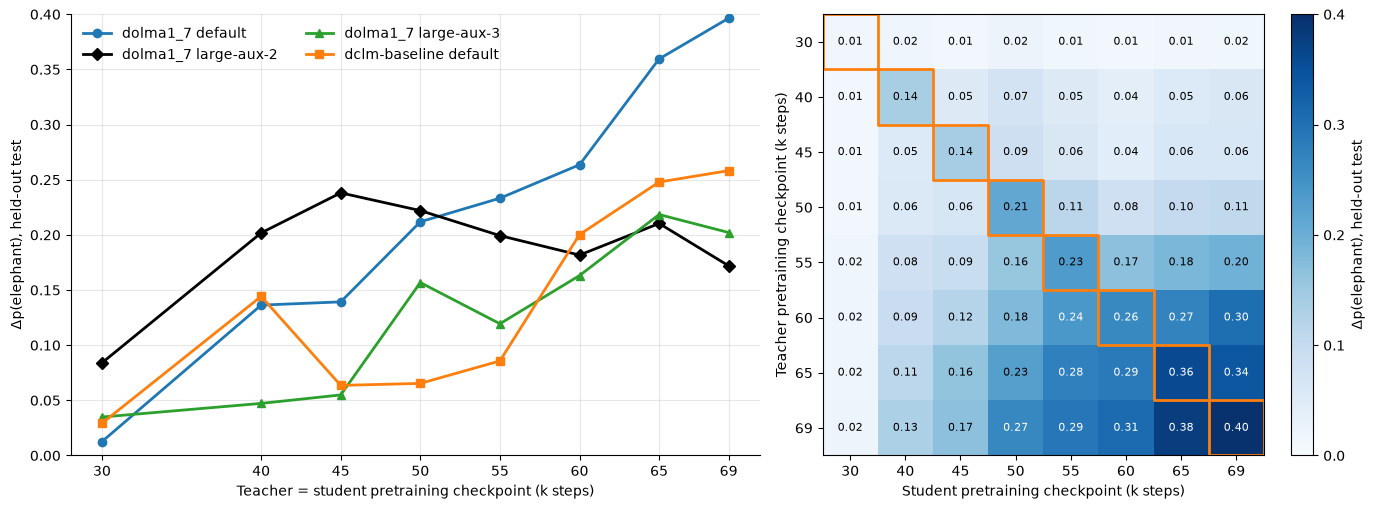

Mc range 0.006 to 0.396
wrote olmo_figure3.png/.pdf/_cells.csv/_provenance.json (256 cell rows); vmin=0.0, vmax=0.4


In [17]:
# Section 4g. OLMo version of paper figure 3: control-subtracted diagonal transfer per grid (left), dolma default 8x8 control-subtracted grid (right); Mc = M - C from cell 4f.
# Pooled grids of cell 14 (all complete recipes, ftseeds 1-3). Axis labels match paper figure 3 (scripts/plot_checkpoint_takeoff.py); y and colour range 0-0.4.
import json, datetime
from matplotlib.patches import Polygon
VMIN, VMAX = 0.0, 0.4  # Mc spans 0.006-0.396 over all four grids
OG = {k: gf.grid_matrix(r, OSTEPS_BY[k]) for k, r in OGRID_RUNS.items()}
OFIG_LABEL = {k: f"{OCORPUS[k[0]]} {k[1].removeprefix('seed-')}" for k in OGRID_RUNS}
kfmt = lambda st: [str(s // 1000) for s in st]
STY = {"seed-default": ("#1f77b4", "o", "-"), "seed-large-aux-2": ("#000000", "D", "-"), "seed-large-aux-3": ("#2ca02c", "^", "-")}
fig, (axl, axr) = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={"width_ratios": [1.25, 1]})
for k, g in OG.items():
    col, mk, ls = STY[k[1]] if k[0] == gf.OLMO_BASE_DOLMA else ("#ff7f0e", "s", "-")
    axl.plot([s / 1000 for s in OSTEPS_BY[k]], np.diag(OMC[k]), color=col, marker=mk, ls=ls, lw=2, ms=6, label=OFIG_LABEL[k])
allst = sorted({s for st in OSTEPS_BY.values() for s in st})
axl.set_xticks([s / 1000 for s in allst], kfmt(allst)); axl.set_ylim(VMIN, VMAX); axl.grid(alpha=0.3)
axl.set_xlabel("Teacher = student pretraining checkpoint (k steps)"); axl.set_ylabel("Δp(elephant), held-out test")
axl.legend(loc="upper left", ncol=2, frameon=False); axl.spines[["top", "right"]].set_visible(False)
DK = (gf.OLMO_BASE_DOLMA, "seed-default"); M, st = OMC[DK], OSTEPS_BY[DK]; n = len(st)
im = axr.imshow(M, cmap="Blues", vmin=VMIN, vmax=VMAX, aspect="auto")
for i in range(n):
    for j in range(n):
        axr.text(j, i, f"{M[i, j]:.2f}", ha="center", va="center", fontsize=8, color="white" if M[i, j] > 0.6 * VMAX else "black")
stair = [(-0.5, -0.5)] + [pt for i in range(n) for pt in ((i + 0.5, i - 0.5), (i + 0.5, i + 0.5))]
stair2 = [(-0.5, -0.5)] + [pt for i in range(n) for pt in ((i - 0.5, i + 0.5), (i + 0.5, i + 0.5))]
for s_ in (stair, stair2):
    axr.plot(*zip(*s_), color="#ff7f0e", lw=2)
axr.set_xticks(range(n), kfmt(st)); axr.set_yticks(range(n), kfmt(st))
axr.set_xlabel("Student pretraining checkpoint (k steps)"); axr.set_ylabel("Teacher pretraining checkpoint (k steps)")
fig.colorbar(im, ax=axr, label="Δp(elephant), held-out test", ticks=np.arange(0, 0.41, 0.1)); fig.tight_layout()
FIG3 = REPO / "notebooks/figures/figure3_checkpoints/olmo/olmo_figure3"; FIG3.parent.mkdir(parents=True, exist_ok=True)
for ext in ("png", "pdf"):
    fig.savefig(f"{FIG3}.{ext}", dpi=200, bbox_inches="tight")
plt.show()
cells = pd.DataFrame([{"corpus": OCORPUS[k[0]], "seed": k[1], "teacher_step": t, "student_step": s, "p_raw": g.M[i, j], "p_control": OCTRL[k].M[i, j], "p_minus_control": OMC[k][i, j], "n_runs": int(g.n_runs[i, j]), "n_runs_control": int(OCTRL[k].n_runs[i, j])}
                      for k, g in OG.items() for i, t in enumerate(OSTEPS_BY[k]) for j, s in enumerate(OSTEPS_BY[k])])
cells.to_csv(f"{FIG3}_cells.csv", index=False)
prov = {"created_utc": datetime.datetime.now(datetime.timezone.utc).isoformat(), "notebook": "notebooks/checkpoint_grid_factorization.ipynb",
        "student_tag": OST, "trait": "elephant", "right_panel": {"base": DK[0], "seed": DK[1]}, "quantity": "p_raw - p_control; controls are matched base-pool controls (load_olmo_base_controls: students distilled on numbers from the unfinetuned base at the same teacher checkpoint), same base, pretraining seed, student tag and steps", "vmin": VMIN, "vmax": VMAX, "x_tick_note": "x ticks are the data's own steps in thousands; 69 = final checkpoint",
        "aggregation": "recipe mean of the ftseed-pooled per-recipe cell means (grid_matrix); complete recipes only",
        "grids": [{"label": OFIG_LABEL[k], "base": k[0], "seed": k[1], "recipes": sorted(r["tag"].unique().tolist()),
                   "steps": [int(s) for s in OSTEPS_BY[k]], "ftseeds": sorted(int(f) for f in r["ftseed"].unique()),
                   "runs_per_cell": {"min": int(OG[k].n_runs.min()), "max": int(OG[k].n_runs.max())},
                   "control_ftseeds": sorted(int(x) for x in OCTRL_RUNS[k]["ftseed"].unique()),
                   "control_ftseeds_per_cell": sorted(int(x) for x in OCTRL_RUNS[k].groupby(["t", "s"])["ftseed"].nunique().unique()),
                   "control_runs_per_cell": {"min": int(OCTRL[k].n_runs.min()), "max": int(OCTRL[k].n_runs.max())}} for k, r in OGRID_RUNS.items()]}
open(f"{FIG3}_provenance.json", "w").write(json.dumps(prov, indent=2))
print(f"Mc range {min(m.min() for m in OMC.values()):.3f} to {max(m.max() for m in OMC.values()):.3f}")
print(f"wrote {FIG3.name}.png/.pdf/_cells.csv/_provenance.json ({len(cells)} cell rows); vmin={VMIN}, vmax={VMAX}")


## 5. Reading

**The product form holds on both model families.** On Pythia-160M the product-plus-proximity model reaches an in-sample $R^2$ of 0.982 on the dog orig grid and 0.953, 0.975 and 0.978 on cat, lion and pig, with cell cross-validation $R^2$ (five folds, five repeats, pooled) of 0.970 for dog (section 2a). On the OLMo elephant grids, all 8×8 and with all fine-tuning seeds pooled, it reaches 0.980 on dolma `seed-default`, 0.980 on dolma `seed-large-aux-3` and 0.974 on DCLM `seed-default`, against 0.773, 0.778 and 0.804 for the additive model, and subtracting the matched base controls leaves these values almost unchanged (0.980, 0.978 and 0.973), so the structure belongs to the transfer itself and not to the control baseline (section 4c).

**On OLMo the product form holds on three of four grids.** The four grids span two pretraining corpora (dolma1_7 on three pretraining seeds, DCLM-baseline on one), each scored on the same 8 checkpoints, with 8, 6, 6 and 5 complete teacher recipes. Dolma `seed-default`, dolma `seed-large-aux-3` and DCLM `seed-default` factorize: plain-product $R^2$ 0.927, 0.927 and 0.940, product-plus-proximity 0.980, 0.980 and 0.974, cross-validated 0.952, 0.947 and 0.941, held-out diagonal 0.821, 0.798 and 0.803, against noise ceilings of 0.994, 0.991 and 0.986. Dolma `seed-large-aux-2` does not: plain product 0.638, product-plus-proximity 0.885 (cross-validated 0.701) against a ceiling of 0.978, and a held-out-diagonal $R^2$ of $-2.707$. The split holds on every fine-tuning seed separately (plain product 0.917 to 0.928 on dolma `seed-default`, 0.903 to 0.939 on `seed-large-aux-3`, 0.921 to 0.939 on DCLM, 0.581 to 0.664 on `seed-large-aux-2`, whose held-out diagonal stays between $-2.625$ and $-1.598$) and when any one teacher recipe is dropped (0.601 to 0.679 on `seed-large-aux-2`, at least 0.919 on the other three), so it is a property of the aux-2 pretraining run and not of one fine-tuning seed or teacher recipe (section 4 and 4a).

**OLMo differs from Pythia in the size of the same-checkpoint bonus, and on both families the grids are asymmetric.** A fit that sees only the off-diagonal cells predicts the OLMo diagonal less well than the Pythia one: the held-out-diagonal $R^2$ of the product-plus-proximity model is 0.798 to 0.821 on the three factorizing OLMo grids, against 0.938 to 0.973 for the four Pythia orig grids. The fitted OLMo bonus is $c$ = 0.046 to 0.101 in probability units with decay lengths of 5k to 10k steps; on Pythia it is 0.107 for the dog orig grid and 0.061 to 0.078 for cat, lion and pig, with decay lengths of 5k to 20k steps (section 2a). The bottleneck model $m(\min(t,s))$ is a close rival on the off-diagonal cells (off-diagonal $R^2$ 0.740 to 0.876 on OLMo, 0.770 to 0.903 on Pythia), but it, the mirror $m(\max(t,s))$ and every other model keyed on $\min$ or $\max$ alone are symmetric by construction, so the antisymmetric part of a grid caps the whole family. That part carries 0.101 to 0.218 of the off-diagonal variance on OLMo and 0.085 to 0.195 on Pythia, at least ten times what seed noise alone would produce (0.010 or less everywhere), and the rank-one product reproduces 0.939 to 0.971 of it on OLMo and 0.879 to 0.924 on Pythia (section 4b). The grids are therefore direction dependent in a way the product captures and no symmetric model can. The fitted OLMo factors peak late: the teacher factor at the final checkpoint on dolma and DCLM `seed-default`, at 60k on `seed-large-aux-3` and 55k on `seed-large-aux-2`, and the student factor at 65k or the final checkpoint on all four grids, whereas the Pythia dog orig teacher factor peaks in the interior at 125k and declines to 0.755 of that value by 143k. Reading each OLMo student at its trajectory peak instead of its endpoint changes nothing material: the peak grid correlates with the endpoint grid at 0.995 or better and the product-plus-proximity $R^2$ is 0.983, 0.894, 0.979 and 0.974 (section 4c).

**Teacher recipe, student recipe and fine-tuning seed change the scale of a grid and not its shape.** On Pythia, the other recipes' fitted curves predict a held-out teacher recipe's dog orig grid with $R^2$ 0.912 after one free scale (section 2b), and a fit to fine-tuning seed 1 predicts the mean of seeds 2 and 3 with $R^2$ 0.971 against a noise ceiling of 0.990. The Pythia student recipe `ep10_lr2e-4_r32a16` read at step 12500 correlates with the reference grid at 0.977 with a scale of 1.172, and the reference's rank-one curves transported with one scalar give $R^2$ 0.956 against its own rank-one ceiling of 0.971. Its fitted curves correlate with the reference's at 0.987 for the teacher factor and 0.995 for the student factor, both recipes' curves peak at 125k (teacher) and 143k (student), and the two recipes' lean scores correlate at a Spearman of 0.841 with no checkpoint changing sign. Read at step 6250 of both student training runs, the two recipes agree about as well as at the later readout, with a cell-wise correlation of 0.979 and a scale of 1.185; on the 48-cell partial grids, the transported curves give 0.938, 0.966 and 0.978 for the rank-8 alpha-4, rank-4 alpha-2 and rank-128 alpha-16 recipes. The exception is the rank-64 alpha-32 recipe, where the transported curves reach only 0.787 although its own rank-one fit reaches 0.992 and its cell-wise correlation with the reference is 0.878 (section 3). On OLMo, the rank-1 student recipe `ep3_lr5e-4_r1a32` exists only on the dolma `seed-default` grid, on 7 checkpoints and 5 complete teacher recipes, so it is held out of the four-grid results above (section 4d). On the 5 teacher recipes it shares with the rank-8 recipe, the two grids correlate cell-wise at 0.980 with the rank-1 grid 1.176 times larger on average, their fitted curves correlate at 0.987 for the teacher factor and 0.993 for the student factor, and transporting the rank-8 curves to the rank-1 grid with one free scale gives $R^2$ 0.863 against its own product fit of 0.887 (0.857 against 0.882 in the other direction). On the three OLMo grids that factorize, a fit to fine-tuning seed 1 predicts the mean of seeds 2 and 3 about as well as a second seed's own measurements do: product-plus-proximity $R^2$ 0.961, 0.966 and 0.950 on dolma `seed-default`, dolma `seed-large-aux-3` and DCLM `seed-default`, against seed-versus-seed $R^2$ of 0.963, 0.944 and 0.871 and noise ceilings of 0.990, 0.986 and 0.969. On dolma `seed-large-aux-2` the cells are reproducible across fine-tuning seeds (cell-wise Pearson 0.919 to 0.954 over the three seed pairs, and seed 1's raw cells predict the other two at 0.925) while their structure is still not a product (plain product 0.576, product-plus-proximity 0.824), and with one teacher recipe held out its product-plus-proximity transport ranges 0.454 to 0.711 against 0.801 to 0.923, 0.599 to 0.950 and 0.785 to 0.932 on the other three grids (section 4e).

**Across traits the curve shapes agree, but verbatim transport of both curves does not work well.** On the four Pythia orig grids the fitted teacher curves of different traits correlate at 0.813 to 0.940 and the student curves at 0.912 to 0.967, and borrowing one curve while refitting the other keeps $R^2$ between 0.753 and 0.942 (section 2c). Taking both curves verbatim from another trait with one free scale, however, gives only 0.535 to 0.786, against each target's own plain product fit of 0.926 to 0.964. The one-curve numbers therefore overstate how much is shared, and forcing one sender and one receiver curve on all four traits at once costs 0.041 (dog) to 0.143 (cat) in $R^2$ (section 2d).